#Introduction to Deep Learning

#Required Reading:

[Chollot, F. 2021. Deep Learning with Python, 2nd Edition:](https://ubc.summon.serialssolutions.com/search?spellcheck=true&s.q=Deep+learning+with+python+%28Fran%C3%A7ois+Chollet%29#!/search?ho=t&include.ft.matches=f&l=en&q=(Deep%20learning%20with%20python)%20AND%20(AuthorCombined:(Fran%C3%A7ois%20Chollet)))
  * Chapter 1. What Is Deep Learning?

**Please complete the quiz before the lecture reading the above**
<!-- Note that text and video versions of this book are available.

*add other readings and some short youtube videos* -->

#1. Introduction

#1.1 Learning from Data

 * Both deep learning and machine learning *learn* by iteratively finding ways to transform or represent input data to reveal patterns which allow for predictions to be made.
  * This is achieved by *studying* examples of inputs and outputs.







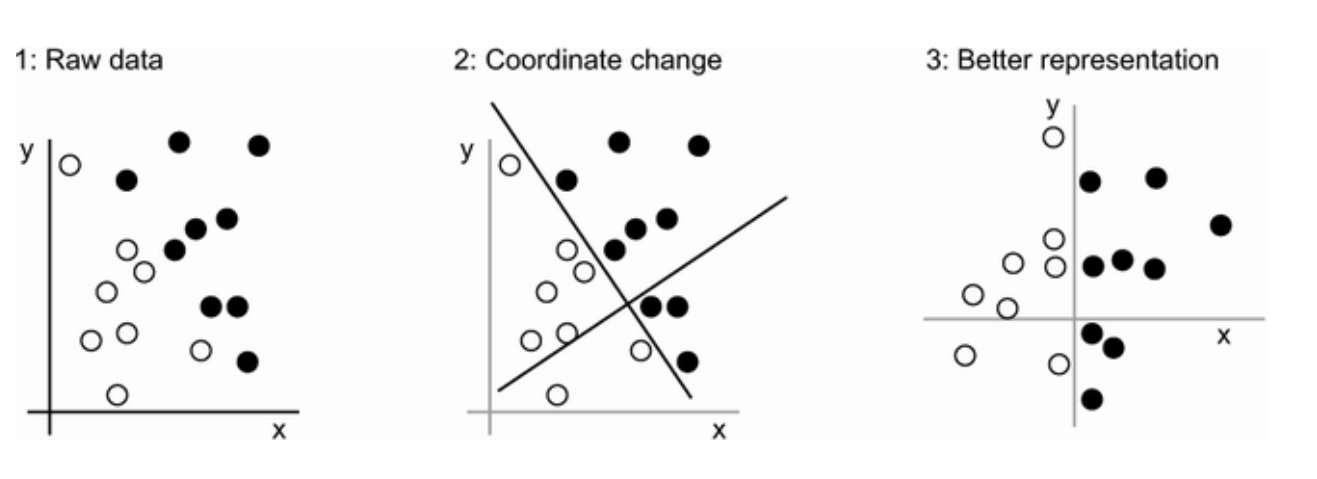

*Figure 1. Coordinate change (Chollet, 2021. Figure 1.4)*

 * Figure 1 displays an example of a simple data transformation that yields a representation of the data that can allow for the black and white data points to be accurately separated.
 * This is of course a simple example. To solve more complex problems, more complex representations are often needed.

 * Most machine learning algorithms learn a limited number of ways to transform input data.
 * As such, machine learning typically benefits from structured data; data which has been selected and organized by a human user before processing by a machine learning algorithm.
  * This structuring of data is also known as *feature engineering*.
* To use remote sensing as an example, it is common practice for users to calculate spectral indices which are later used as input in machine learning models.
  * For example, NDVI, the Normalized Difference Vegetation Index, is calculated as a ratio of red and near infrared (NIR) reflectance (Figure 2).
    * Because heathy vegetation reflects NIR light and absorbs red light, NDVI is a useful indicator of vegetation health.
    * NDVI is commonly used as input in machine learning models and is favoured over simply inputting NIR and Red reflectance values.

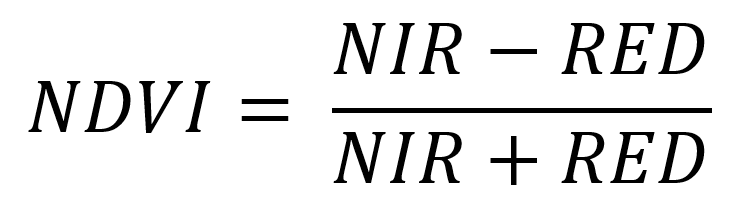

*Figure 2. NDVI.*

#1.2 Deep learning

 * Deep learning differs from machine learning in that deep learning is able automate the process of feature engineering.
 * This is done with **Neural Networks**
 * Neural networks are comprised of layers of nodes (otherwise known as neurons), where each node represents a unique way to transform the data.
 * By stacking deep layers of nodes, neural networks are able to create many unique representations of the data.
 * It is from the depth of neural network layers that the term *Deep Learning* comes from.

*Let's take a look at the basic structure of a neural network to gain a better understanding*

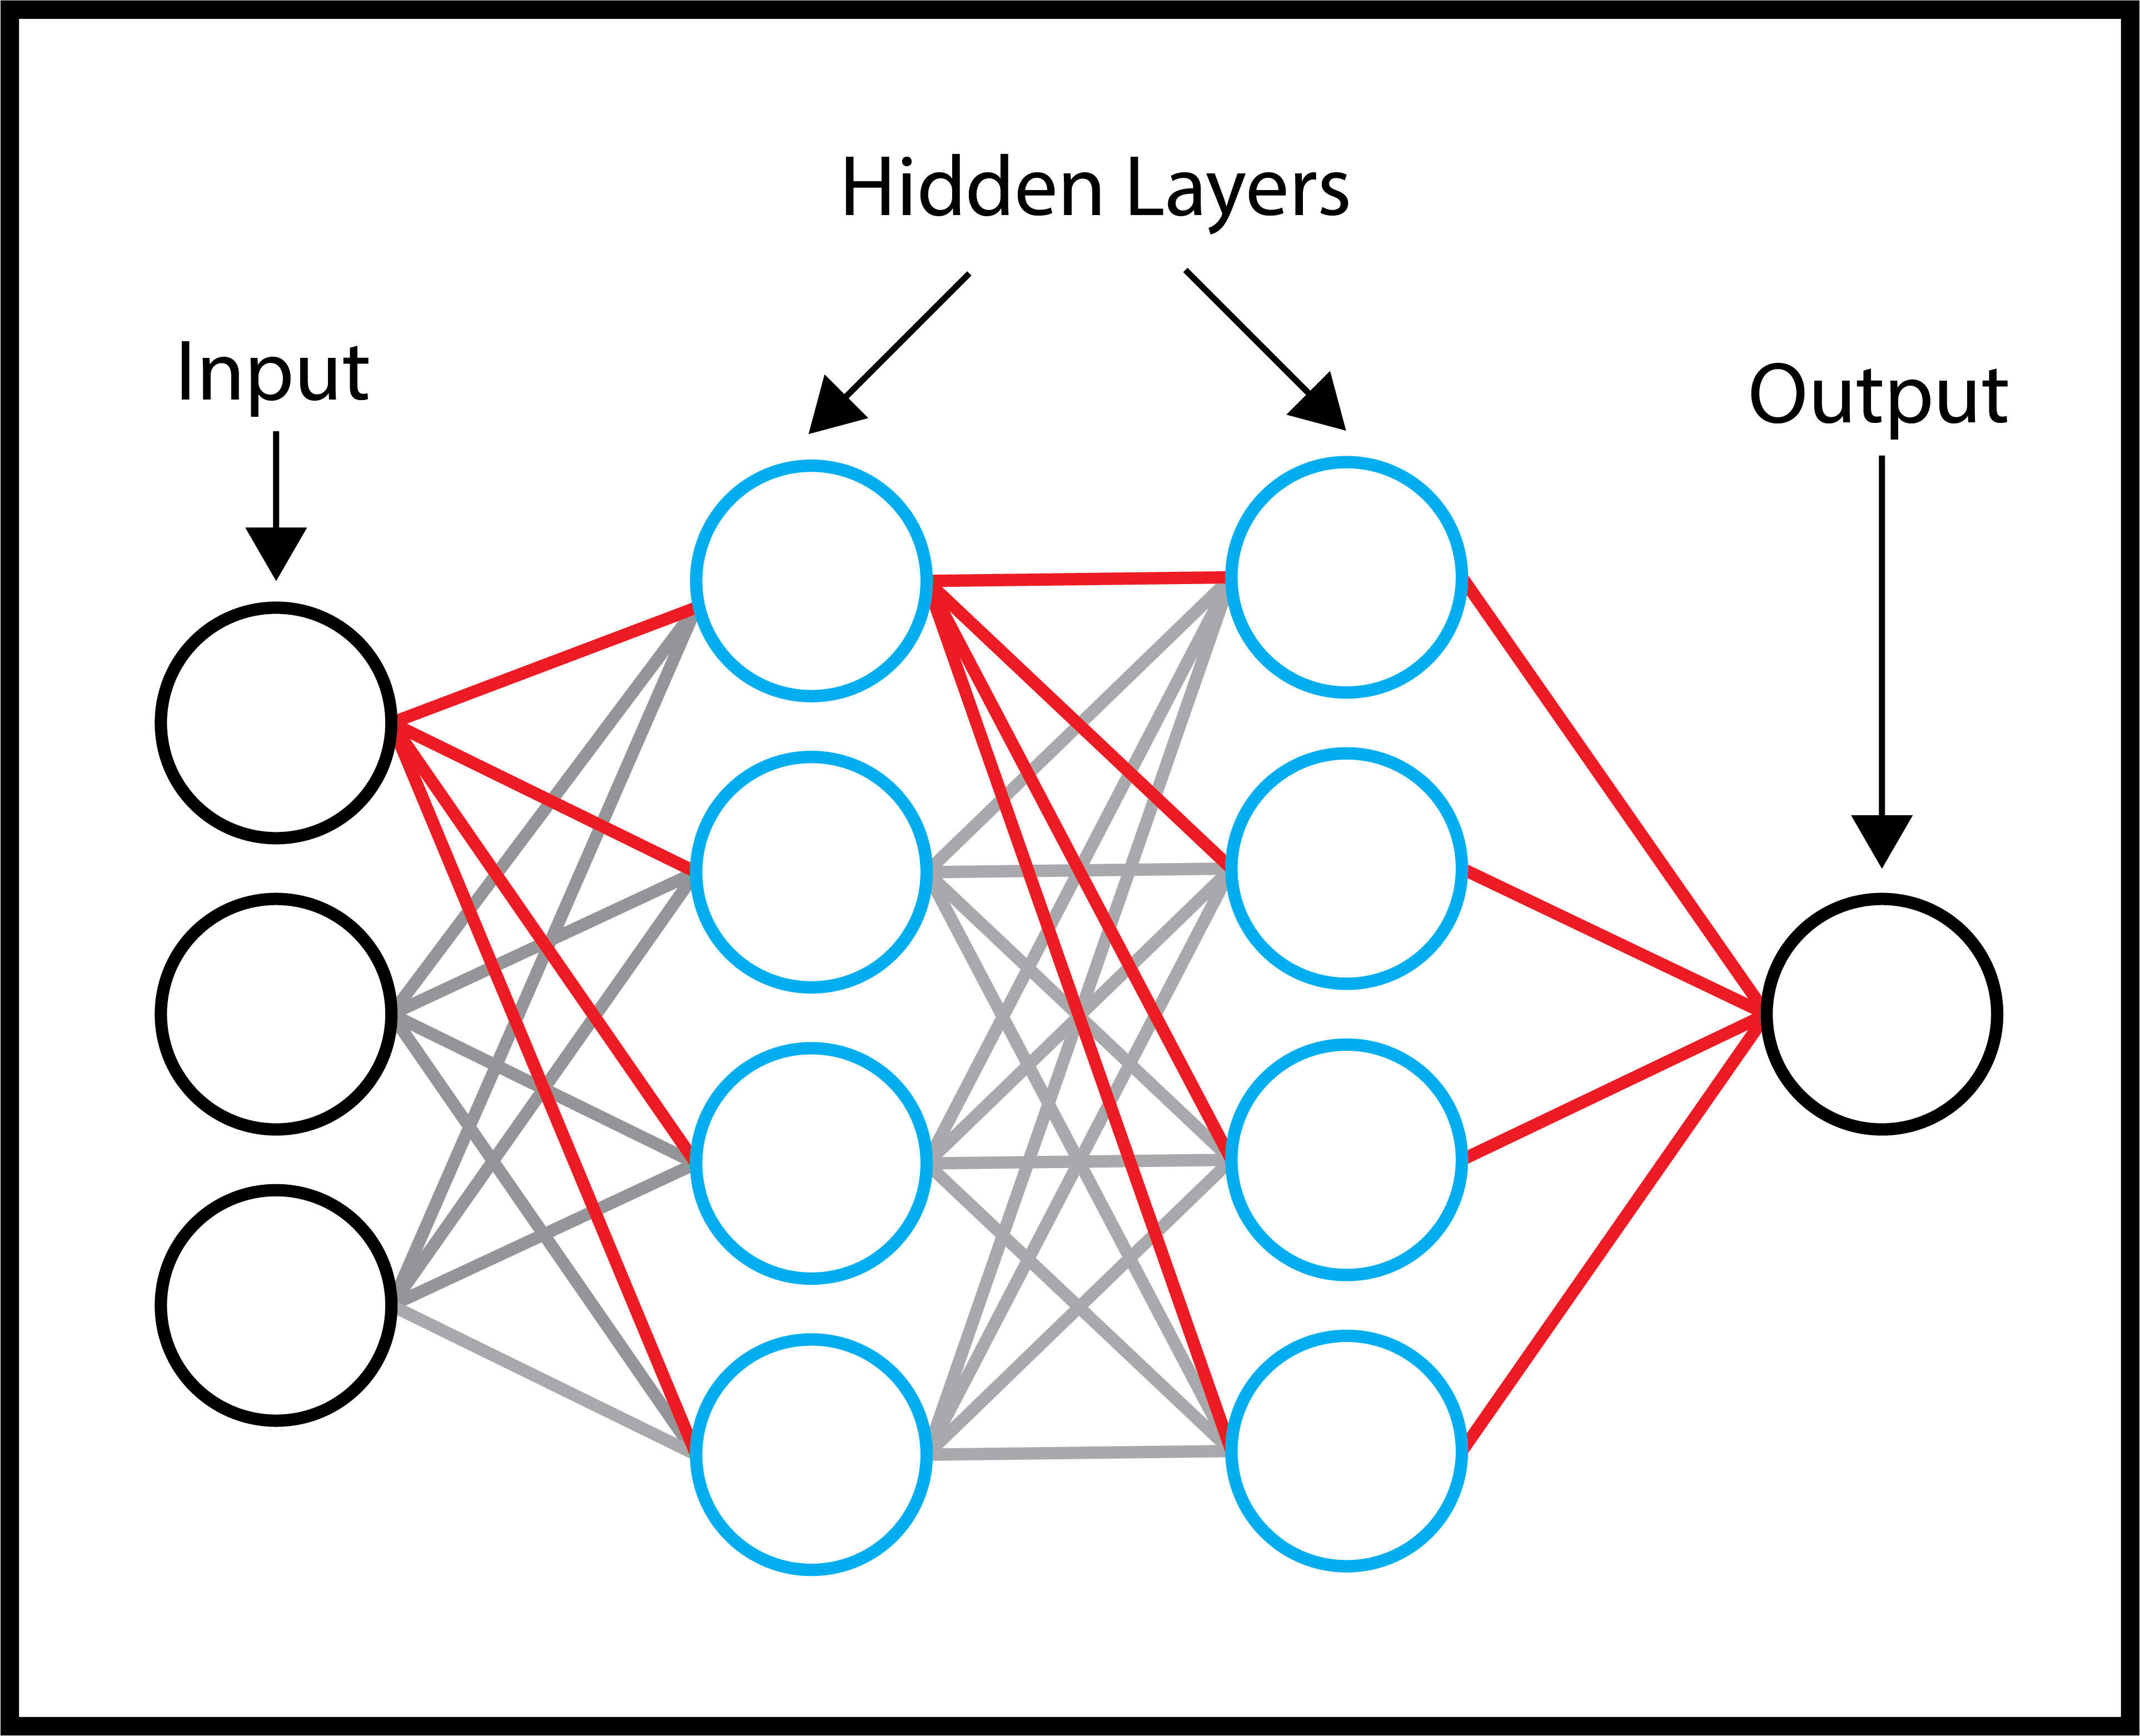

*Figure 3. Basic Neural Network Structure.*

 * In this figure, each layer is represented by a vertical stack of circles.
 * These circles represent nodes, which comprise each layer.
  * Note that this is a simplified diagram and neural network layers are typically much deeper than shown in Figure 3.
 * Connections between nodes are represented by lines.  
 * In this example, each node in a layer is connected to a node in a subsequent layer.
  *  **This type of neural network is called a fully connected neural network.**
 * Connections originating from the first node of each layer are coloured red for emphasis.  

The most basic components of neural networks are an Input Layer, Hidden Layers, and an Output Layer.


**The Input Layer** is equal to whatever input you are feeding the Neural Network. For example, if you are training a network on tabular data, each node in the input layer would represent a row in a table.

**The Output Layer** is what the network is predicting. For example, in this lecture, we will train a network to predict a continous variable (tree height) using other information. In this case, our output will be a single value. However, in other situations, for example, tree species classification, our output layer will have a size equal to the number of species being classified, where each value in the output layer corresponds to the probability of a tree belonging to a species class.

**The Hidden Layers** are where all the magic happens. The reason these layers are called *Hidden* is because users typically only observe the Input and Output layers. As such, what goes on in the Hidden Layers is hidden. However, as we'll see in this lecture, this does not mean that we cannot inspect and understand what is happening during each hidden layer.

Each node within a hidden layer (displayed as blue circles) contains a set of transformations that that node will apply to the data. The goal of these transformations is to expose patterns in the data. The first hidden layer will receive the Input Layer as input, whereas the second hidden layer will receive the transformations of the first hidden layer as input.

#1.3 Hidden layer nodes

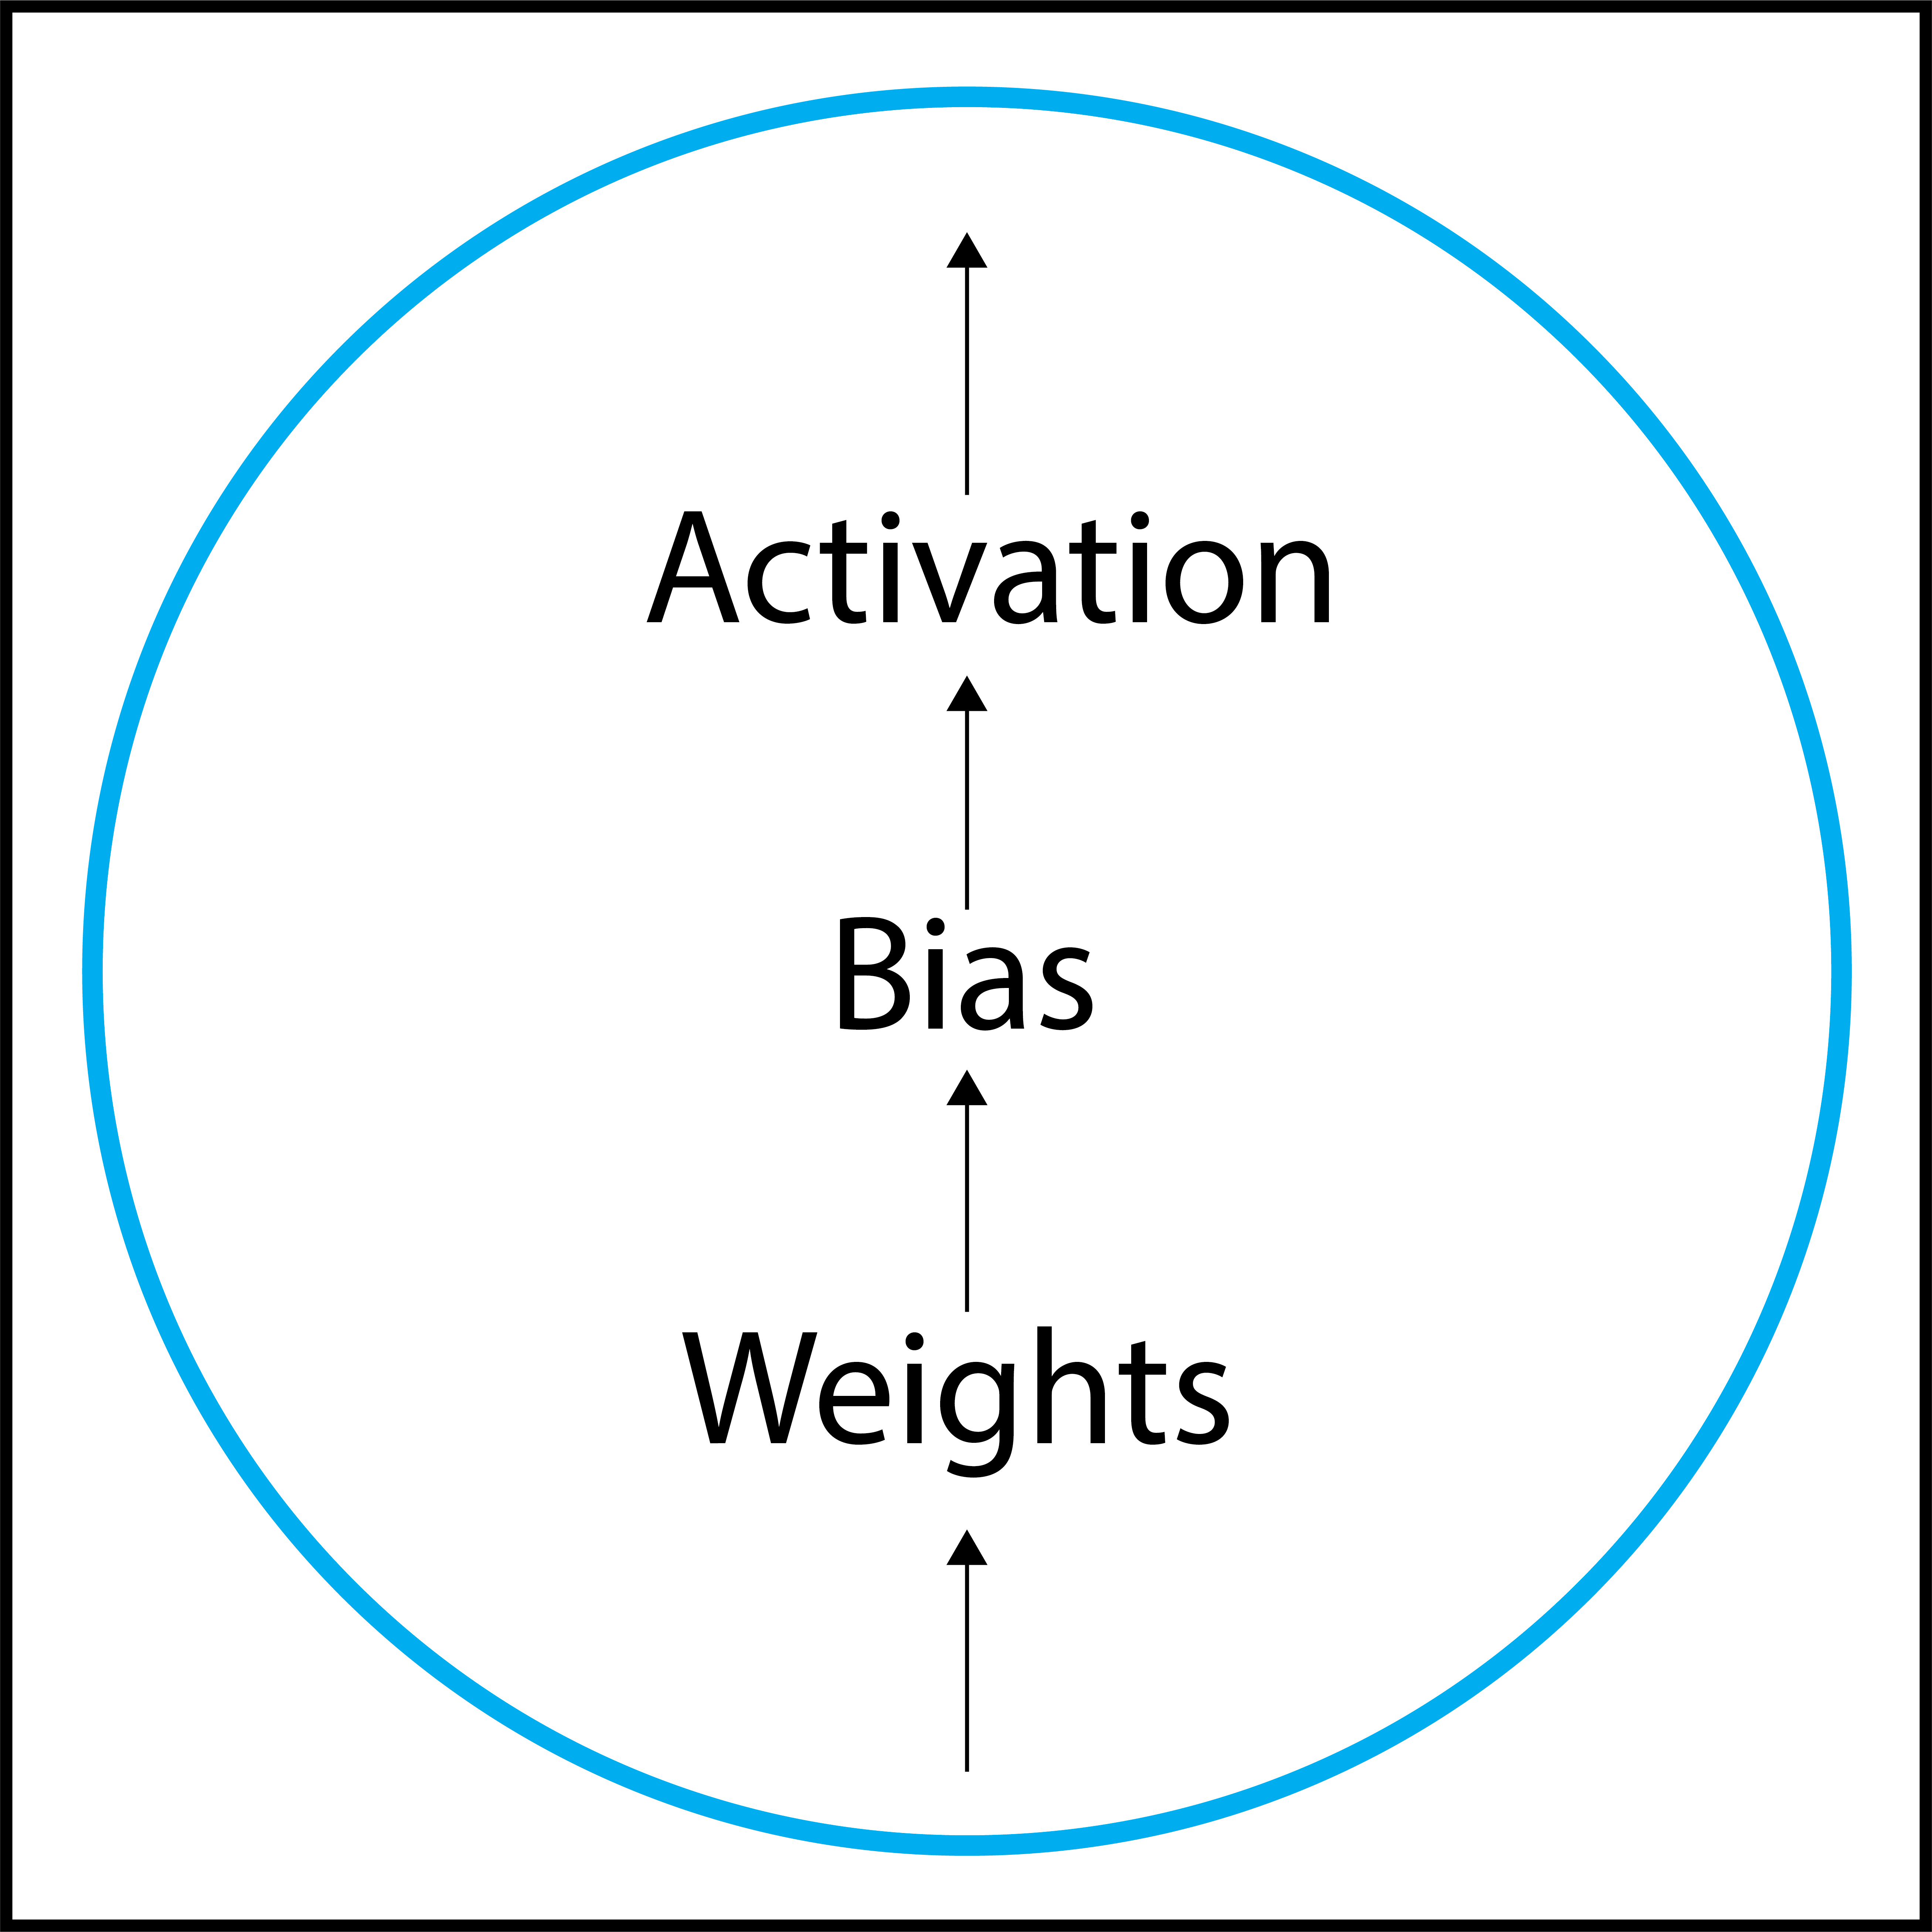

*Figure 2. A simplified node in a hidden layer.*


Each node contains a set of **Weights** values and a single **Bias** value.
 * These are numeric values that are used to transform the input data (we will discuss the details of how the input data is actually transformed later on).
 * The actual values of the weights and bias are initialized randomly.
 * As it studies the provided examples, a neural network will adjust weights and bias values so as to transform the input data in more meaningful ways, which will allow it to make accurate predictions.
 * As such, weights and bias are considered to be learnable parameters.

The **Activation** function is a non-linear transformation that is applied after the transformations applied by the weights and bias. Activation functions are defined for each hidden layer and therefore are applied to all nodes within a hidden layer.

**Let's look at an example below:**

weights_nodes.png

*Figure 3. Transformation applied by a single node.*

In this lecture, we will build a deep neural network (DNN) to predict a continuous variable using 8 independent variables. Before we get to that, let's look at how a single node in the DNN will transform the input data.

In this example, we have 8 independent variables, our input data. This is equal to the first row of table.

**We're looking at the first node of our first layer.** This node has weight values equal to the number of inputs - in this case, 8.

 * The first step of the node's transformation is to retrieve the dot product of the input and weights vectors.
  * The first step of applying the dot product is to perform pair-wise multiplication.
  * In this example, we take the first input value, -0.37, and multiply it by the first weight value, -2.32. The product of this multiplication is 0.86.
  * When then multiply the second input value by the second weight value and store the product, -0.49.
  * Once we have done this for all inputs and weights, we sum the products. The sum of these products is called the dot product, 0.35.

* We then add the node's bias value to the dot product. This returns a value of 2.44.
* Finally, we apply our activation function. In this example we're using the 'relu' function, which stands for rectified linear unit.
 * Put simply, relu will return all values greater than 0. If the relu input value is negative, it will return a value of 0.
* The output of the activation function then becomes the first input value for the next layer of the DNN.
* The output of the second node will become the second input value for the next layer of the DNN, and so on.
* Eventually, when the data reaches the output layer, which has a size of 1 (1 node), the dot product of that layer's input and the output layer node's weights, plus the output layer node's bias will be the final output.
 * In this case, we are not using an activation function for the output layer.


 In summary, A node processes its inputs by computing the dot product of inputs and weights, adding a bias, and passing the result through an optional activation function (like ReLU) before sending it to the next layer. This continues layer by layer until the final output node computes its dot product plus bias to produce the network's output.

  

#1.4 How are weights and bias adjusted?

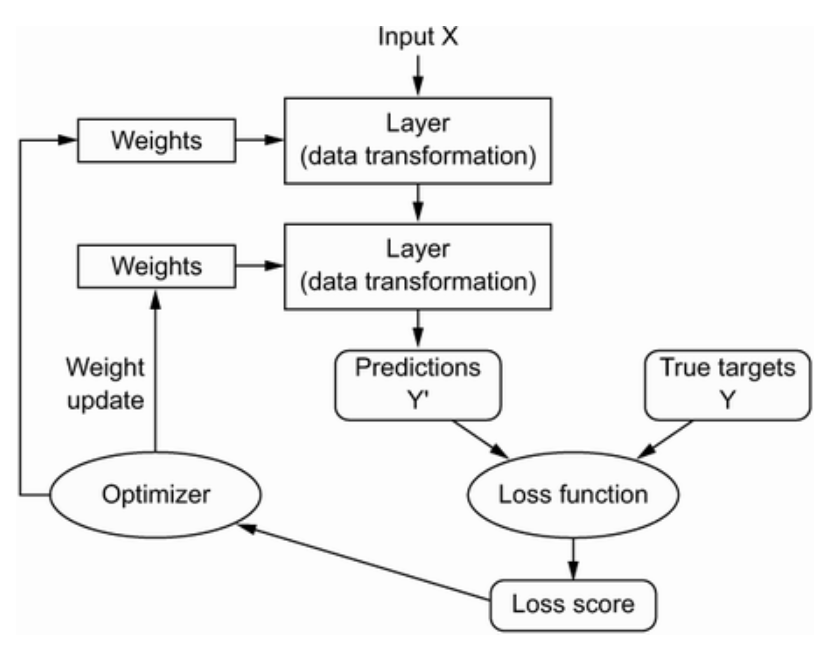

*Figure 4. Relationship between the network, layers, loss function, and optimizer (Chollet, 2021. Figure 2.26).*  



 * Neural networks learn from examples.
 * This learning is performed during what is called a training loop, wherein the network iteratively *studies* the training data.
 * For each sample provided, the network will transform the input data to make predictions and assess itself using the provided true values and a **Loss Function**.
  * A loss function is essentially a means to calculate a metric (the **Loss Score**). For example, for a regression task, it is common to use *mean sqaured error* as the loss function.
 * The network feeds the loss score into an **Optimizer** that moves backwards through the layers of the network and adjusts the weight and bias values of each node in each layer so as the reduce the loss score.
 * One iteration of the training loop has occured once the network has examined each training example once. **This is called an epoch.**
  * Note that the functionality of optimizers is complex and beyond the scope of this course. For this reason, they will not be discussed further in this lecture. If you would like to learn more about deep learning, you are encouraged to explore the rest of the recommended text.



* Because the network is constantly exposed to the training data, there is a chance that it will *memorize* weight and bias values to improve the loss score instead of *learning* generalized values during each epoch. **This is called Overfitting**.
* For this reason, it is standard practice to reserve a percentage of the training data as validation data.
 * This validation data subset is withheld during the training loop and instead is used at the end of each epoch to generate a second loss score (called **Validation Loss**), which is used to update weight and bias values at the end of each epoch.





#2. Building a Deep Neural Network (DNN) to Predict a Continuous Variable with Tabular Data.

For this example, we will build a DNN to predict the height of regenerating trees using information extracted from remotely sensed data.

**Background**


Tree height is one of the main determinants of regeneration success. As such, it is important to measure. Tree height can be estimated with remote sensing using digital aerial photogrammetry. However, these methods can be time consuming and results may be subject to error due to conditions at regenerating stands.

Aerial imagery is easier to consistently collect than accurate photogrammetric products. We can process aerial imagery so as to delineate individual tree crowns (ITC). These delineated ITC can in turn be used to extract spectral information from the imagery in addition to ITC area estimates. This information may be useful for predicting tree height. If so, this method of predicting tree height may save time and money in future forest regeneration monitoring efforts.

**About the data**


* To collect the data for this example, we delineated ITC as polygons (.shp).
* We then used these ITC polygons to extract spectral information from associated drone imagery (zonal statistics).
* The spectral information is comprised of the mean and variance for the Red, Green, and Blue bands of the imagery within each tree crown.
* We will also use the area of each ITC as input for our DNN.
* This data was compiled as a .csv table.

<!-- **To explore the code used to produce this data**, please see the *Week11_zonal_statistics* script, available in the course onedrive. -->

Note that the power of neural networks is not necessarily fully utilized when they are applied to tabular data, and other machine learning techniques may prove more effective in this domain as we will see later.

However, we are using tabular data as a starting point so as to bridge machine learning methods learned earlier in this course with deep learning. In this way, we will provide you with the tools required to explore deep learning techniques with your own datasets.

Furthermore, to determine the suitability of deep learning for this example versus other machine learning options, we will also predict tree height using multiple linear regression and Random Forest.

#2.1 Import Required Packages

We will build our DNN from scratch using the keras Sequential API, which is built on Tensorflow.

In lines 1-5 we import the necessary tensorflow and keras components

We will also use some modudles from the sklearn package:
 * We will use *train_test_split* to split our data into training and testing data
 * Additionally, we will use the *StandardScaler* module to normalize our data. This process is explained later on.  


**First, lets connect to google drive**

In [ ]:
# To load a data file from google drive we need to mount it first and then locate the file.
# We need to run the following to mount our drive and get a location
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


**Import required packages**

We will be using *Keras* to build our DNN, which is built on *Tensoflow*

We will also use some modules from *sklearn* for pre-processing

In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

#2.1 Reading the data

<!-- Download the *csv* from the course onedrive -->

Download the *csv* from the week 11 module on canvas

Open the Files icon on the right side of the screen. Navigate to the `drive` folder, then open the `MyDrive` folder. Place your data file in this folder (or in any other location you prefer).

For example, you might create a directory structure like this:
/content/drive/MyDrive/week11/zonal_output312.csv

Once you've placed the file, update the file path in the cell below so your code can correctly load the data.



Line 1: read the csv with pandas (pd)

Line 2: call the dataset.head() to inspect the first five entries in the table.

In [ ]:
dataset = pd.read_csv(r'/content/drive/MyDrive/week11/zonal_output312.csv')
dataset.head()

,area,height,red_mean,red_std,blue_mean,blue_std,green_mean,green_std,Lodgepole_Pine,White_Spruce
0,4.3155,550,114.602920,39.041108,115.444004,36.129785,76.197497,42.728681,1,0
1,0.9486,222,161.047438,20.787751,153.542694,21.861726,153.884250,22.272375,1,0
2,4.5414,442,108.392390,29.626694,118.138327,33.332836,60.079667,22.950618,1,0
3,4.1022,625,100.973892,38.676105,115.168276,38.862862,53.887889,30.351169,1,0
4,1.9188,385,110.790338,33.633435,125.810976,33.630335,55.937617,23.802253,1,0


#About this dataset
 * area is measured in square metres
 * height is measured in centimetres
 * the spectral information is derived from reflectance values
 * the species information is categorical: **0** equals lodgepole pine and **1** equals white spruce.

#2.2 Splitting the Data into Training and Testing Subsets

 * First, we will separate our independent (X) and dependent (y) variables into different dataframes.


In [ ]:
X = dataset.drop('height', axis=1)
y = dataset['height']

* Next, we will use *train_test_split* to further split our data into training and testing subsets
* For this, we will reserve 20% (0.2) of our dataset for testing.
* This split will be made randomly. In order to repeat this in the future, we set a *random_state* value

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

#2.3 Normalization
 * Our features vary quite a bit from each other.
 * The *area* column has values ranging from 0.03 to 6.25
 * Whereas our spectral information ranges from 0 to 255 and our categorical species values (*Lodgepole_Pine* and *White_Spruce*) are either 0 or 1.


 * Models tend to be biased towards larger values and as such it will be easier for our models to find patterns in this data if all features are within a similar range.

 * To achieve this, we will employ **Normalization** using the *StandardScaler* module.

 * This module takes the value of each cell, subtracts that value from the mean of all values in that column, and divides the result of that subtraction by the square root of variance in that column.
 * For more information, see the module's [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Building our DNN

Line 1: First, we define our model as a variable named *model* using Sequential from keras.

 * Now we can add components to our model with the *.add* function.

Line 2: Here we add the first *dense* or *hidden* layer.

 * The first argument we provide is the number of nodes in this layer, 8.
  * Note that this is a small number of nodes.
  * This number was chosen to facilitate visualizations later on.  
 * The second argument we provide is the dimensions of our input data, which is equal to the number of columns in our dataset, 9.
  * Note that we only need to specify in the input dimensions for the first dense layer.
 * The third argument  we provide is the activation function that nodes in this layer will use.
 * The fourth argument we provide is a name for this layer. This can be any arbitrary string. We will use this name for organization.
  * We will use the *relu* or *rectified linear unit* activation function, which we will explain in more detail later on.

Line 3: Here we define our second *dense* or *hidden* layer.
  * This layer is identical to the first dense layer.

Line 4: Here we define our output layer. Because we are predicting a single, continous value, the size of our output layer is 1.

Line 5: In the above lines, we defined our model. Here we compile it.
 * We define the loss function (*loss*) our model will use to score itself (*mean_squared_error*).
 * We define *adam* as our optimizer.
 * We define *mean absolute error* (*'mae'*) as a metric for our model to report during training.
  * Note that mean absolute error will not be used by the model to score itself. Rather, we will use it later on to evaluate our model's performance.

Line 6: Finally, we call model.summary() to print a summary of the DNN model we have build and compiled.  


In [ ]:
model = Sequential()
model.add(Dense(8, input_dim=9, activation='relu', name='Dense_Hidden_1'))
model.add(Dense(8, activation='relu', name='Dense_Hidden_2'))
model.add(Dense(1, name='Output'))

model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Dense_Hidden_1 (Dense)          │ (None, 8)              │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Hidden_2 (Dense)          │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (644.00 B)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

In the above summary we can see each of the layers we have defined in addition to their shapes and the number of parameters associated with each layer.

#2.5 Training our DNN

Here we will initiate the training of our DNN model.

  * We will store our training history as a variable called *history*.
  * The first two arguments we provide are the scaled independent values, *X_train_scaled* and the dependent values, *y_train*.
  * The third argument we provide is the percentage of the training data that is to be used as validation data. We will use 20% or *0.2*.
  * The fourth argument we provide is the number of epochs that the DNN will train for, 1000.
  * Finally, we will use a technique called *Early Stopping*.
   * This ensures that if the DNN is no longer improving during training, it will stop training early and revert to the epoch with the lowest validation loss score.
    * Within callbacks, we specify early stopping with a patience of 50. This means that early stopping will trigger if the DNN vaidation loss score continously worsens for 50 epochs.

In [ ]:
history = model.fit(X_train_scaled,
                    y_train,
                    validation_split=0.2,
                    epochs=1000,
                    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=200, restore_best_weights=True)])

Epoch 1/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 500ms/step - loss: 149229.6562 - mae: 352.9001 - val_loss: 137553.5781 - val_mae: 332.5177
Epoch 2/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 152481.3750 - mae: 357.5705 - val_loss: 137517.3906 - val_mae: 332.4743
Epoch 3/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 151192.5625 - mae: 355.9921 - val_loss: 137482.0156 - val_mae: 332.4318
Epoch 4/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 147452.4531 - mae: 350.1877 - val_loss: 137447.7500 - val_mae: 332.3902
Epoch 5/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 156108.0938 - mae: 363.9639 - val_loss: 137414.4062 - val_mae: 332.3498
Epoch 6/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 149715.3125 - mae: 355.2674 - val_loss: 137382.6250 - val_mae: 332.3112
Epoch 7/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 143933.5938 - mae: 346.6012 - val_loss: 137351.5781 - val_mae: 332.2736
Epoch 8/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 146711.8906 - mae: 350.

#2.6 Evaluation

With training complete, we can retrieve the training and validation loss as well as the training and validation mean absolute error scores from the history variable and use matplotlib to plot this data.

In [ ]:
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


acc = history.history['mae']
val_acc = history.history['val_mae']
plt.plot(epochs, acc, 'y', label='Training MAE')
plt.plot(epochs, val_acc, 'r', label='Validation MAE')
plt.title('Training and validation MAE')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In the figures produced above, we can see that the training and validation loss converged after about 375 epochs. After this point, the loss values continued to decrease, but at a diminished rate. We can see that the mean absolute error values behave similarly in the second figure.

The convergence of training and validation loss indicates that the DNN model successfully learned a generalized solution to the problem.

Conversely, if the training loss were to continue to decrease while the validation loss increased, this would indicate that the model was *memorizing* the training data to improve its loss score. In this case, the validation loss would increase because this *memorization* would not allow the model to generalize and correctly predict on the validation data.

In addition to visualizing the model's training history, we can visualize the model's predictions versus the actual values.

Let's make a function to do this so that we can quickly visualize the results of other methods we'll use later on.

In [ ]:
def plot_preds(predictions, test_labels, title):
  a = plt.axes(aspect='equal')
  plt.scatter(test_labels, predictions)
  plt.xlabel('True Values [Tree Height]')
  plt.ylabel('Predictions [Tree Height]')
  lims = [0, 700]
  plt.xlim(lims)
  plt.ylim(lims)
  line = plt.plot(lims, lims)
  plt.title(title)

To obtain the predicted values, we use the *predict* function.
We can then enter these values into the function we created above.

In [ ]:
dnn_predictions = model.predict(X_test_scaled).flatten()
plot_preds(dnn_predictions, y_test, 'dnn')

Let's collect the mean squared error and mean absolute error values from our trained model for comparison later on.

In [ ]:
mse_dnn, mae_dnn = model.evaluate(X_test_scaled, y_test, verbose=0)
print('Mean squared error from DNN: ', mse_dnn)
print('Mean absolute error from DNN: ', mae_dnn)

We can also calculate rmse (root mean sqaured error) and r2 values.
Let's make a function for this for use later on.

In [ ]:
from sklearn.metrics import r2_score

def rmse_r2(predictions, true_values, mse, name):
  predicted = np.squeeze(predictions)

  rmse = np.sqrt(mse)
  print('{} Test RMSE: {:.20f}'.format(name, rmse))

  r2 = r2_score(true_values, predicted)
  print('{} Test R^2 Score: {:.5F}'.format(name, r2))

  return rmse, r2

In [ ]:
dnn_rmse, dnn_r2 = rmse_r2(dnn_predictions, y_test, mse_dnn, 'dnn')

#3. Comparison to machine learning methods.

#3.1 Multiple Linear Regression

For linear regression, we'll use the sklearn package.

Line 4: Define the model

Line 5: Fit the model

Line 6: Predict on the test data

Lines 7 & 8: Obtain mean squared error and mean absolute error for comparison

Line 11: Use the function we made earlier to retrieve rmse and r2 for comparison.

In [ ]:
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, mean_absolute_error

lr_model = linear_model.LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
mse_lr = mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
print('Mean squared error from linear regression: ', mse_lr)
print('Mean absolute error from linear regression: ', mae_lr)
lr_rmse, lr_r2 = rmse_r2(y_pred_lr, y_test, mse_lr, 'lr')

Let's use our plotting function to see the predicted versus actual values.

In [ ]:
plot_preds(y_pred_lr, y_test, 'linear_regression')

We can see that multiple linear regression outperformed our DNN for this task.

What about Random Forest?

#3.2 Random Forest

We'll use the Random Forest Regressor from sklearn.


In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=30, random_state=30)
rf_model.fit(X_train_scaled, y_train)

y_pred_RF = rf_model.predict(X_test_scaled)

mse_RF = mean_squared_error(y_test, y_pred_RF)
mae_RF = mean_absolute_error(y_test, y_pred_RF)
print('Mean squared error using Random Forest: ', mse_RF)
print('Mean absolute error Using Random Forest: ', mae_RF)
rf_rmse, rf_r2 = rmse_r2(y_pred_RF, y_test, mse_RF, 'rf')

In [ ]:
plot_preds(y_pred_RF, y_test, 'random forest')

Let's gather all evaluation metrics and compare.



In [ ]:
compare = pd.DataFrame({'method': ['dnn', 'linear_regression', 'random_forest'],
                        'mse': [mse_dnn, mse_lr, mse_RF],
                        'mae': [mae_dnn, mae_lr, mae_RF],
                        'rmse': [dnn_rmse, lr_rmse, rf_rmse],
                        'r2': [dnn_r2, lr_r2, rf_r2]}
                       )
compare

We can see that Random Forest outperformed both the multiple linear regression model and our DNN model.

#3.3 A Deeper DNN

The DNN we created earlier was actually quite shallow...

This may be why it did not perform as well as linear regression and random forest.

Let's build a deeper DNN with more layers and more nodes per layer and see how it performs:

In [ ]:
model2 = Sequential()
model2.add(Dense(128, input_dim=9, activation='relu', name='Dense_Hidden_1'))
model2.add(Dense(64, activation='relu', name='Dense_Hidden_2'))
model2.add(Dense(64, activation='relu', name='Dense_Hidden_3'))
model2.add(Dense(32, activation='relu', name='Dense_Hidden_4'))
model2.add(Dense(1, name='Output'))

model2.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])
model2.summary()

In [ ]:
history2 = model2.fit(X_train_scaled,
                      y_train,
                      validation_split=0.2,
                      epochs=1000,
                      callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=200, restore_best_weights=True)])

In [ ]:
dnn_predictions2 = model2.predict(X_test_scaled).flatten()
plot_preds(dnn_predictions2, y_test, 'dnn2')

In [ ]:
mse_dnn2, mae_dnn2 = model2.evaluate(X_test_scaled, y_test, verbose=0)
print('Mean squared error from DNN: ', mse_dnn2)
print('Mean absolute error from DNN: ', mae_dnn2)

In [ ]:
dnn2_rmse, dnn2_r2 = rmse_r2(dnn_predictions2, y_test, mse_dnn2, 'dnn2')

Take some time to reflect, based on what we have learned in this course, what do these values indicate?

In [ ]:
compare.loc[4] = ['dnn2', mse_dnn2, mae_dnn2, dnn2_rmse, dnn2_r2]
compare

 * We can see that the deeper DNN (dnn2) performed much better than the original DNN.
  * It also took much fewer epochs to train.

 * However, the second DNN still comparible to the linear regression model and was still outperformed by the random forest model.

  * It seems that random forest is better suited for this type of task.

 * One thing to note is that the dataset we used for this example is quite small (128 rows/samples).

* This type of neural network is likely better suited for large datasets with rows/samples upwards of 10,000., as well as more columns.

 * In the next section of this lecture, we'll look at a task better suited for deep learning, image classification.
